# Multi-agent RL: can a wolf pack learn to pick the easy prey?

Three **wolves** hunt a herd of **three deer** in a meadow with rocks. In 80% of hunts, one of the three is a **fawn**. The question this notebook asks: **will the pack learn to go after the fawn?**

**The deer.** Adult deer are a little faster than a wolf (a bonus move every 3rd step), so a single wolf chasing one can never catch it. **The fawn never gets the bonus move**, so in principle it's the easiest target. Nothing in the rewards says so: a fawn kill pays exactly the same as an adult kill. If the pack prefers the fawn, it's because it *learned* that fawns are easier to catch.

**Bites and kills.** Wolves only land bites when a deer has no escape route left (rocks, edges, wolves and other deer all block exits), so the pack has to work together to trap it. Every deer has 5 health. **A hunt ends at the first kill**, so each hunt records one choice of prey.

**What the wolves see.** For every deer: where it is, **whether it's a fawn**, its health and its open exits. So the information needed to pick the fawn is right there; the open question is whether DQN learns to use it.

**The wolves** learn with DQN plus two standard multi-agent ideas:
- **Parameter sharing:** all three wolves use **one** network. Each wolf feeds it the world as seen from its own position and gets its own action back.
- **Team reward:** every bite rewards **all** wolves, not just the biter, so blocking an exit pays off when a packmate lands the bite.

**The key measurement** is the **fawn share of kills**: in hunts that include a fawn, how often was the kill the fawn? A pack that ignores deer type and picks randomly would land near 1/3. The baselines below show what simple hand-written strategies achieve, including one that always chases the fawn.

In [111]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "3")   # set before numpy/torch load: more BLAS threads just spin and starve the hunt workers
import json, uuid, warnings, traceback
import multiprocessing as mp
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque
from IPython.display import HTML, display

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # AMD GPUs also show up as "cuda"; set "cpu" to compare
DEVICE = torch.device("cpu")
torch.set_num_threads(1)   # the net is tiny: spreading each op over many CPU cores costs more than it saves
print("training on", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

rng = np.random.default_rng(0)
torch.manual_seed(0)

training on CPU


## 1. Sprites
Simple hand-written SVG sprites. The animations below move them around a grass background. All sprites face right; they get mirrored when an animal moves left. The fawn is smaller and spottier, with no antlers.

In [112]:
CELL = 44   # pixels per grid cell in the drawings (the grass tile below matches it)

SPRITES = """<svg width="0" height="0" style="position:absolute"><defs>
<pattern id="grass" width="44" height="44" patternUnits="userSpaceOnUse">
  <rect width="44" height="44" fill="#cfe8b0"/>
  <path d="M8,30 l2,-6 l2,6 M28,14 l2,-6 l2,6 M34,38 l2,-5 l2,5 M16,10 l1.5,-4 l1.5,4"
        stroke="#94c46f" stroke-width="1.5" fill="none"/>
</pattern>

<symbol id="wolf" viewBox="-50 -50 100 100">
  <path d="M-28,-4 Q-46,-8 -46,-26 Q-36,-12 -24,-12 Z" fill="#59616b" stroke="#2b3036" stroke-width="2.5" stroke-linejoin="round"/>
  <rect x="-22" y="6" width="8" height="26" rx="3" fill="#4a5058" stroke="#2b3036" stroke-width="2"/>
  <rect x="-10" y="6" width="8" height="26" rx="3" fill="#6b7480" stroke="#2b3036" stroke-width="2"/>
  <rect x="10" y="6" width="8" height="26" rx="3" fill="#4a5058" stroke="#2b3036" stroke-width="2"/>
  <rect x="21" y="6" width="8" height="26" rx="3" fill="#6b7480" stroke="#2b3036" stroke-width="2"/>
  <ellipse cx="0" cy="-2" rx="30" ry="15" fill="#6b7480" stroke="#2b3036" stroke-width="2.5"/>
  <ellipse cx="2" cy="7" rx="19" ry="5" fill="#a7afb8"/>
  <path d="M22,-14 L25,-36 L33,-20 Z" fill="#59616b" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <path d="M31,-18 L37,-38 L42,-17 Z" fill="#59616b" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <circle cx="33" cy="-10" r="12" fill="#6b7480" stroke="#2b3036" stroke-width="2.5"/>
  <path d="M38,-15 L49,-8 L46,-1 L36,-1 Z" fill="#a7afb8" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <circle cx="47" cy="-7" r="2.6" fill="#111"/>
  <circle cx="35" cy="-14" r="2.4" fill="#ffd23f" stroke="#111" stroke-width="1"/>
</symbol>

<symbol id="deer" viewBox="-50 -50 100 100">
  <rect x="-22" y="2" width="5" height="32" rx="2" fill="#7a4e28"/>
  <rect x="-13" y="2" width="5" height="32" rx="2" fill="#94603a"/>
  <rect x="13" y="2" width="5" height="32" rx="2" fill="#7a4e28"/>
  <rect x="21" y="2" width="5" height="32" rx="2" fill="#94603a"/>
  <path d="M-23,31 h7 v4 h-7 Z M-14,31 h7 v4 h-7 Z M12,31 h7 v4 h-7 Z M20,31 h7 v4 h-7 Z" fill="#2b1a0e"/>
  <ellipse cx="0" cy="-2" rx="28" ry="13" fill="#b9814a" stroke="#5e3b1c" stroke-width="2.5"/>
  <ellipse cx="-30" cy="-8" rx="6" ry="5" fill="#fff8ec" stroke="#5e3b1c" stroke-width="2"/>
  <circle cx="-8" cy="-8" r="2.2" fill="#fff8ec"/><circle cx="2" cy="-10" r="2.2" fill="#fff8ec"/>
  <circle cx="-3" cy="-4" r="1.8" fill="#fff8ec"/><circle cx="8" cy="-5" r="1.8" fill="#fff8ec"/>
  <path d="M16,-8 L25,-28 L34,-24 L27,-2 Z" fill="#b9814a" stroke="#5e3b1c" stroke-width="2.5" stroke-linejoin="round"/>
  <path d="M28,-34 L22,-46 M25,-40 L17,-43 M33,-35 L38,-48 M36,-42 L44,-45"
        stroke="#6b4423" stroke-width="3" stroke-linecap="round" fill="none"/>
  <ellipse cx="35" cy="-28" rx="11" ry="7.5" fill="#c99560" stroke="#5e3b1c" stroke-width="2.5"/>
  <ellipse cx="24" cy="-33" rx="6" ry="3" fill="#b9814a" stroke="#5e3b1c" stroke-width="2" transform="rotate(-30 24 -33)"/>
  <circle cx="45" cy="-27" r="2.4" fill="#2b1a0e"/>
  <circle cx="36" cy="-30" r="2" fill="#2b1a0e"/>
</symbol>

<symbol id="fawn" viewBox="-50 -50 100 100">
 <g transform="translate(0,9) scale(0.78)">
  <rect x="-22" y="2" width="5" height="32" rx="2" fill="#b07a45"/>
  <rect x="-13" y="2" width="5" height="32" rx="2" fill="#c58c55"/>
  <rect x="13" y="2" width="5" height="32" rx="2" fill="#b07a45"/>
  <rect x="21" y="2" width="5" height="32" rx="2" fill="#c58c55"/>
  <path d="M-23,31 h7 v4 h-7 Z M-14,31 h7 v4 h-7 Z M12,31 h7 v4 h-7 Z M20,31 h7 v4 h-7 Z" fill="#2b1a0e"/>
  <ellipse cx="0" cy="-2" rx="28" ry="13" fill="#d9a066" stroke="#7a4e28" stroke-width="2.5"/>
  <ellipse cx="-30" cy="-8" rx="6" ry="5" fill="#fff8ec" stroke="#7a4e28" stroke-width="2"/>
  <circle cx="-14" cy="-6" r="2.4" fill="#fff8ec"/><circle cx="-6" cy="-9" r="2.4" fill="#fff8ec"/>
  <circle cx="2" cy="-5" r="2.2" fill="#fff8ec"/><circle cx="10" cy="-8" r="2.2" fill="#fff8ec"/>
  <circle cx="-9" cy="-1" r="1.8" fill="#fff8ec"/><circle cx="6" cy="0" r="1.8" fill="#fff8ec"/><circle cx="16" cy="-3" r="1.8" fill="#fff8ec"/>
  <path d="M16,-8 L25,-28 L34,-24 L27,-2 Z" fill="#d9a066" stroke="#7a4e28" stroke-width="2.5" stroke-linejoin="round"/>
  <ellipse cx="35" cy="-28" rx="11" ry="7.5" fill="#e3b07a" stroke="#7a4e28" stroke-width="2.5"/>
  <ellipse cx="23" cy="-35" rx="8" ry="3.5" fill="#d9a066" stroke="#7a4e28" stroke-width="2" transform="rotate(-35 23 -35)"/>
  <circle cx="45" cy="-27" r="2.4" fill="#2b1a0e"/>
  <circle cx="36" cy="-30" r="2.4" fill="#2b1a0e"/>
 </g>
</symbol>

<symbol id="rock" viewBox="-50 -50 100 100">
  <path d="M-38,30 L-42,4 L-24,-24 L6,-34 L32,-18 L42,10 L34,32 Z" fill="#8d8f94" stroke="#4a4c50" stroke-width="3" stroke-linejoin="round"/>
  <path d="M-24,-20 L4,-29 L22,-18 L0,-12 Z" fill="#b4b6ba"/>
  <path d="M-10,8 L10,2 L22,14" stroke="#5f6166" stroke-width="2.5" fill="none"/>
</symbol>

<symbol id="bite" viewBox="-50 -50 100 100">
  <polygon points="0,-46 11,-16 42,-24 20,0 44,22 12,16 0,46 -12,16 -44,22 -20,0 -42,-24 -11,-16"
           fill="#ff3b30" stroke="#8b0000" stroke-width="3" stroke-linejoin="round"/>
  <polyline points="-18,-6 -12,8 -6,-6 0,8 6,-6 12,8 18,-6" fill="none" stroke="#fff" stroke-width="4" stroke-linejoin="round"/>
</symbol>
</defs></svg>"""

def sprite_box(name, label):
    return (f'<div style="text-align:center"><svg width="96" height="96"><rect width="96" height="96" rx="8" fill="url(#grass)"/>'
            f'<use href="#{name}" x="8" y="8" width="80" height="80"/></svg><div>{label}</div></div>')

display(HTML(SPRITES + '<div style="display:flex;gap:24px">' +
             "".join(sprite_box(n, l) for n, l in [("wolf", "wolf"), ("deer", "deer"), ("fawn", "fawn"), ("rock", "rock"), ("bite", "bite!")]) + "</div>"))

## 2. The hunt: rules, the deer's brain, and what each wolf sees

In [113]:
SIZE         = 12          # meadow is SIZE x SIZE
N_WOLVES     = 3
N_DEER       = 3           # a hunt ends at the first kill
FAWN_CHANCE  = 1 #0.8        # chance that one of the deer is a fawn
ROCK_DENSITY = 0.09        # chance each cell is a rock
DEER_HP      = 5           # fawns have the same health; their only difference is no bonus move
MAX_STEPS    = 85
DEER_RANDOM  = 0.05        # chance per move that a deer panics and moves randomly
DEER_EXTRA_EVERY = 2 # 3       # adult deer get a bonus move every N steps (0 = never); fawns never do
SPOOK_DIST   = 1           # a deer won't stand still with a wolf this close
BITE_MAX_EXITS = 0         # bites land only when a deer has at most this many open exits
VIEW         = 4           # each wolf sees rocks within 8 cells of itself
GAMMA        = 0.975       # discount factor used by training

# Rewards (shared by the whole pack unless noted). A fawn kill pays the same as an adult kill.
BITE_REWARD, KILL_REWARD, STEP_COST = 1.0, 15.0, 0.01
# Shaping: small hints that count the wolves' own moves, measured before the deer react. They can be "farmed"
# (chasing a deer that keeps running away earns +0.1 every step), but in tests they're what gets learning started:
# potential-based versions that subtract the deer's escape left the pack stuck at a 0% kill rate.
CHASE_SHAPING = 0.1        # per wolf: +0.1 for each cell it moves closer to its nearest deer
PIN_SHAPING   = 0.2        # team: +0.2 for each exit the pack closes off on the most-trapped deer

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]   # up, down, left, right, stay
GRID_R, GRID_C = np.mgrid[:SIZE, :SIZE]

def dist(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def connected(rocks):
    """True if every open cell can reach every other one (no sealed-off pockets)."""
    free = [tuple(p) for p in np.argwhere(~rocks)]
    seen, queue = {free[0]}, deque([free[0]])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ACTIONS[:4]:
            n = (r + dr, c + dc)
            if 0 <= n[0] < SIZE and 0 <= n[1] < SIZE and not rocks[n] and n not in seen:
                seen.add(n); queue.append(n)
    return len(seen) == len(free)

def random_arena(rng):
    """Random rocks, N_DEER deer (one of them a fawn with chance FAWN_CHANCE), and wolves starting
    at least 4 steps from every deer. Returns (rocks, deer, fawn, wolves); fawn[k] says whether deer k is a fawn."""
    while True:
        rocks = rng.random((SIZE, SIZE)) < ROCK_DENSITY
        if not connected(rocks):
            continue
        free = [tuple(int(v) for v in p) for p in np.argwhere(~rocks)]
        order = rng.permutation(len(free))
        deer = [free[i] for i in order[:N_DEER]]
        wolves = [free[i] for i in order[N_DEER:] if min(dist(free[i], d) for d in deer) >= 4][:N_WOLVES]
        if len(wolves) < N_WOLVES:
            continue
        fawn = [False] * N_DEER
        if rng.random() < FAWN_CHANCE:
            fawn[rng.integers(N_DEER)] = True
        return rocks, deer, tuple(fawn), wolves


class Hunt:
    def __init__(self, rocks, deer, fawn, wolves):
        self.rocks, self.deer0, self.fawn, self.wolves0 = rocks, deer, fawn, wolves
        self.padded = np.pad(rocks.astype(np.float32), VIEW, constant_values=1)   # off-map = rock
        self.reset()

    def reset(self):
        self.deer, self.wolves = list(self.deer0), list(self.wolves0)
        self.hp, self.t, self.bites, self.killed = [DEER_HP] * N_DEER, 0, [], []
        return self.observe()

    def blocked(self, p, ignore_wolf=None, ignore_deer=None):
        """Off the map, a rock, or a cell taken by another animal."""
        r, c = p
        if not (0 <= r < SIZE and 0 <= c < SIZE) or self.rocks[r, c]:
            return True
        return (any(w == p for i, w in enumerate(self.wolves) if i != ignore_wolf)
                or any(d == p for k, d in enumerate(self.deer) if k != ignore_deer))

    def exits(self, k, p=None):
        """For deer k (standing at p, default its own cell): is each neighbour (up, down, left, right) open?"""
        p = self.deer[k] if p is None else p
        return [not self.blocked((p[0] + dr, p[1] + dc), ignore_deer=k) for dr, dc in ACTIONS[:4]]

    # ---- the deer's brain (fixed rule, not learned) ----
    def territory(self, p):
        """Cells a deer at p could reach before any wolf (straight-line grid distance)."""
        W = np.array(self.wolves)
        wolf_d = (np.abs(GRID_R[..., None] - W[:, 0]) + np.abs(GRID_C[..., None] - W[:, 1])).min(-1)
        return (np.abs(GRID_R - p[0]) + np.abs(GRID_C - p[1]) < wolf_d) & ~self.rocks

    def deer_options(self, k):
        d = self.deer[k]
        return [d] + [(d[0] + dr, d[1] + dc) for (dr, dc), ok in zip(ACTIONS[:4], self.exits(k)) if ok]

    def deer_move(self, k):
        options = self.deer_options(k)
        if len(options) > 1 and min(dist(w, self.deer[k]) for w in self.wolves) <= SPOOK_DIST:
            options = options[1:]                       # a wolf is right there: no standing still
        if rng.random() < DEER_RANDOM:
            return options[rng.integers(len(options))]
        score = lambda p: self.territory(p).sum() + 0.5 * sum(self.exits(k, p)) + 0.1 * rng.random()
        return max(options, key=score)

    # ---- what each wolf sees ----
    def observe(self):
        """One row per wolf, from that wolf's point of view."""
        exits = [self.exits(k) for k in range(N_DEER)]
        rows = []
        for i, (r, c) in enumerate(self.wolves):
            herd = []
            for k in sorted(range(N_DEER), key=lambda k: dist(self.deer[k], (r, c))):   # nearest deer first
                d = self.deer[k]
                herd += [(d[0] - r) / SIZE, (d[1] - c) / SIZE, float(self.fawn[k]), max(self.hp[k], 0) / DEER_HP, *exits[k]]
            packmates = sorted((w for j, w in enumerate(self.wolves) if j != i), key=lambda w: dist(w, (r, c)))
            pack_offsets = [v for w in packmates for v in ((w[0] - r) / SIZE, (w[1] - c) / SIZE)]
            nearby_rocks = self.padded[r:r + 2 * VIEW + 1, c:c + 2 * VIEW + 1].ravel()
            rows.append(np.concatenate([[r / SIZE, c / SIZE], herd, pack_offsets, nearby_rocks]))
        return np.array(rows, np.float32)

    # ---- one tick of the hunt ----
    def step(self, actions):
        """All wolves move, bites are checked, then every deer flees.
        Returns (obs, per-wolf rewards, terminal, outcome)."""
        old_dist = [min(dist(w, d) for d in self.deer) for w in self.wolves]
        old_exits = min(sum(self.exits(k)) for k in range(N_DEER))
        for i in rng.permutation(N_WOLVES):            # wolves move one at a time, in random order
            dr, dc = ACTIONS[actions[i]]
            target = (self.wolves[i][0] + dr, self.wolves[i][1] + dc)
            if not self.blocked(target, ignore_wolf=i):  # rocks, edges, wolves and deer all block
                self.wolves[i] = target
        self.t += 1

        trapped = [sum(self.exits(k)) <= BITE_MAX_EXITS for k in range(N_DEER)]
        self.bites = []                                  # (wolf, deer index); each wolf bites at most once
        for w in self.wolves:
            prey = [k for k in range(N_DEER) if trapped[k] and dist(w, self.deer[k]) == 1]
            if prey:
                k = min(prey, key=lambda k: self.hp[k])  # next to two trapped deer: bite the weaker one
                self.bites.append((w, k)); self.hp[k] -= 1
        self.killed = [k for k in range(N_DEER) if self.hp[k] <= 0]
        exits = min(sum(self.exits(k)) for k in range(N_DEER))
        team = BITE_REWARD * len(self.bites) + PIN_SHAPING * (old_exits - exits) - STEP_COST
        rewards = np.array([team + CHASE_SHAPING * (old_dist[i] - min(dist(w, d) for d in self.deer))
                            for i, w in enumerate(self.wolves)], np.float32)
        if self.killed:                                  # a kill ends the hunt
            return self.observe(), rewards + KILL_REWARD, True, "kill"

        for k in rng.permutation(N_DEER):               # deer flee one at a time, in random order
            self.deer[k] = self.deer_move(k)
            if DEER_EXTRA_EVERY and not self.fawn[k] and self.t % DEER_EXTRA_EVERY == 0:
                self.deer[k] = self.deer_move(k)         # adults only: the fawn never gets the bonus move
        return self.observe(), rewards, False, "escaped" if self.t >= MAX_STEPS else None

def prey(env):
    """What the hunt killed: "fawn", "adult", or None."""
    return None if not env.killed else "fawn" if any(env.fawn[k] for k in env.killed) else "adult"

OBS_DIM = Hunt(*random_arena(rng)).observe().shape[1]
print("each wolf sees", OBS_DIM, "numbers")

each wolf sees 111 numbers


**What each wolf sees** (all relative to itself, so the same network works for every wolf):
- its own position
- for **each deer**, nearest first: its offset from the wolf, **whether it's a fawn**, its health, and which of its 4 exits are open
- each packmate's offset, nearest packmate first
- rocks within `VIEW` cells (off-map counts as rock)

Deer and packmate positions are exact and cover the whole meadow; `VIEW` only limits rocks.

### When does a bite land?
Same rule as before: a deer is bitten only when all 4 of its neighbouring cells are blocked. With a herd, **another deer counts as a blocker too**.

In [114]:
def board_svg(uid, rocks, deer, wolves, bites=(), cell=CELL):
    """One meadow as SVG. deer = [(r, c, facing, is_fawn)]; wolves = [(r, c, facing)]; bites = [(y, x)] in cell units.
    Each animal is a <g class="mover"> that the animation player slides around."""
    rows, cols = rocks.shape
    W, H = cols * cell, rows * cell
    s = [f'<svg id="{uid}" width="{W}" height="{H}" viewBox="0 0 {W} {H}" style="border-radius:6px;display:block">',
         f'<rect width="{W}" height="{H}" fill="url(#grass)"/>']
    s += [f'<line x1="{c * cell}" y1="0" x2="{c * cell}" y2="{H}" stroke="#b9da9d"/>' for c in range(1, cols)]
    s += [f'<line x1="0" y1="{r * cell}" x2="{W}" y2="{r * cell}" stroke="#b9da9d"/>' for r in range(1, rows)]
    s += [f'<use href="#rock" x="{c * cell}" y="{r * cell}" width="{cell}" height="{cell}"/>' for r, c in np.argwhere(rocks)]

    def animal(name, el_id, r, c, facing=1):
        return (f'<g id="{el_id}" class="mover" style="transform:translate({(c + .5) * cell}px,{(r + .5) * cell}px)">'
                f'<g transform="scale({facing},1)"><use href="#{name}" x="{-cell / 2}" y="{-cell / 2}" '
                f'width="{cell}" height="{cell}"/></g></g>')
    s += [animal("fawn" if is_fawn else "deer", f"{uid}_d{k}", r, c, f) for k, (r, c, f, is_fawn) in enumerate(deer)]
    s += [animal("wolf", f"{uid}_w{i}", *w) for i, w in enumerate(wolves)]
    for i in range(len(wolves)):                       # bite bursts, hidden unless a bite happens
        y, x = bites[i] if i < len(bites) else (-9, -9)
        s.append(f'<use id="{uid}_b{i}" href="#bite" x="{(x + .5) * cell - cell * .3}" y="{(y + .5) * cell - cell * .3}" '
                 f'width="{cell * .6}" height="{cell * .6}" visibility="{"visible" if i < len(bites) else "hidden"}"/>')
    return "".join(s) + "</svg>"

def facing(frm, to, default=1):
    return 1 if to[1] > frm[1] else -1 if to[1] < frm[1] else default

def example(deer, wolves, rock_cells=(), herd=(), n=4):
    rocks = np.zeros((n, n), bool)
    for p in rock_cells: rocks[p] = True
    taken = set(wolves) | set(herd)
    exits = sum(0 <= deer[0] + dr < n and 0 <= deer[1] + dc < n and not rocks[deer[0] + dr, deer[1] + dc]
                and (deer[0] + dr, deer[1] + dc) not in taken for dr, dc in ACTIONS[:4])
    bites = ([((w[0] + deer[0]) / 2, (w[1] + deer[1]) / 2) for w in wolves if dist(w, deer) == 1]
             if exits <= BITE_MAX_EXITS else [])
    animals = [(*deer, 1, False)] + [(*h, -1, False) for h in herd]
    return board_svg(uuid.uuid4().hex, rocks, animals, [(*w, facing(w, deer)) for w in wolves], bites, cell=40), exits

cases = [("Pinned in a corner<br>2 wolves → <b>BITE</b>", (0, 0), [(0, 1), (1, 0)], (), ()),
         ("Pinned against the edge<br>3 wolves → <b>BITE</b>", (0, 2), [(0, 1), (0, 3), (1, 2)], (), ()),
         ("Using a rock as a 4th wall<br>3 wolves → <b>BITE</b>", (2, 2), [(2, 1), (2, 3), (3, 2)], [(1, 2)], ()),
         ("A herd-mate blocks an exit<br>2 wolves → <b>BITE</b>", (0, 2), [(0, 1), (1, 2)], (), [(0, 3)]),
         ("One exit left<br><b>no bite</b>: it escapes upward", (2, 2), [(2, 1), (2, 3), (3, 2)], (), ())]
html = '<div style="display:flex;gap:18px;flex-wrap:wrap">'
for label, d, ws, rk, hd in cases:
    svg, ex = example(d, ws, rk, hd)
    html += f'<div style="text-align:center">{svg}<div style="margin-top:4px">{label}</div></div>'
display(HTML(SPRITES + html + "</div>"))

### The deer's brain
Each deer looks at each move it could make (including standing still, unless a wolf is right next to it), counts how many cells it would **own**, meaning cells it could reach before any wolf, and picks the move with the most. Wolves that all chase from the same side just push it into open space. To trap a deer, the pack has to spread out and shrink its territory from several sides. Fawns use the same rule; they just never get the bonus move.

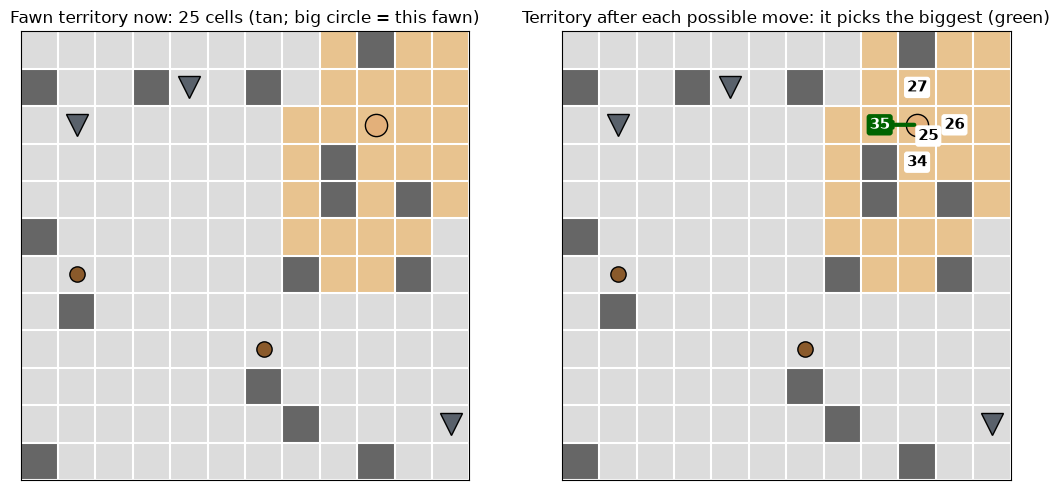

In [115]:
env = Hunt(*random_arena(np.random.default_rng(17)))
k = env.fawn.index(True) if any(env.fawn) else 0          # show the fawn's view if there is one
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
own = env.territory(env.deer[k])
for ax in axes:
    ax.imshow(np.where(env.rocks, 2, own.astype(int)), cmap=ListedColormap(["#dcdcdc", "#e8c38f", "#666666"]), vmin=0, vmax=2)
    for j, d in enumerate(env.deer):
        ax.plot(d[1], d[0], "o", ms=16 if j == k else 11, color="#e3b07a" if env.fawn[j] else "#8a5a2b", mec="k")
    for w in env.wolves:
        ax.plot(w[1], w[0], "v", ms=16, color="#59616b", mec="k")
    ax.set_xticks(np.arange(-.5, SIZE), minor=True); ax.set_yticks(np.arange(-.5, SIZE), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
who = "Fawn" if env.fawn[k] else "Deer"
axes[0].set_title(f"{who} territory now: {own.sum()} cells (tan; big circle = this {who.lower()})")
scores = {o: env.territory(o).sum() for o in env.deer_options(k)}
best = max(scores, key=scores.get)
for o, s in scores.items():
    y, x = (o[0] + .3, o[1] + .3) if o == env.deer[k] else o     # "stay" label sits beside the deer
    axes[1].text(x, y, str(s), ha="center", va="center", fontsize=11, fontweight="bold", zorder=5,
                 color="white" if o == best else "k",
                 bbox=dict(boxstyle="round,pad=0.2", fc="darkgreen" if o == best else "white", ec="none"))
axes[1].annotate("", xy=(best[1], best[0]), xytext=(env.deer[k][1], env.deer[k][0]),
                 arrowprops=dict(arrowstyle="->", lw=3, color="darkgreen") if best != env.deer[k] else None)
axes[1].set_title("Territory after each possible move: it picks the biggest (green)")
plt.tight_layout(); plt.show()

## 3. Baselines
Before training, two non-learning packs (random wolves, which never kill, appear in section 6):
- **chasing wolves**: the whole pack greedily chases whichever deer is nearest to it, ignoring deer type. This is the obvious strategy, and it's what the learned pack needs to beat on kill rate.
- **fawn-chasing wolves**: the same, except the pack always chases the fawn when there is one. This shows how much targeting the fawn is actually worth here.

**Fawn share of kills** only counts hunts that include a fawn. A pack that picks prey at random would land near 1/3.

In [116]:
def pack_chase(pick_target):
    """A pack where every wolf greedily steps toward the deer chosen by pick_target(env)."""
    def policy(obs, env):
        target = env.deer[pick_target(env)]
        acts = []
        for w in env.wolves:
            def cost(a):
                n = (w[0] + ACTIONS[a][0], w[1] + ACTIONS[a][1])
                return (99 if n != w and env.blocked(n) else dist(n, target)) + 0.1 * rng.random()   # next to it: stay put
            acts.append(min(range(len(ACTIONS)), key=cost))
        return acts
    return policy

nearest_deer = lambda env: min(range(N_DEER), key=lambda k: sum(dist(w, env.deer[k]) for w in env.wolves))
fawn_first = lambda env: env.fawn.index(True) if any(env.fawn) else nearest_deer(env)
chase_policy, fawn_chase_policy = pack_chase(nearest_deer), pack_chase(fawn_first)
random_policy = lambda obs, env: rng.integers(len(ACTIONS), size=N_WOLVES)

def run_hunt(env, policy):
    """Play one hunt. Returns (outcome, steps, bites, prey, frames) with frames ready for the animation player."""
    obs = env.reset()
    face = {**{("d", k): 1 for k in range(N_DEER)}, **{i: facing(w, env.deer[0]) for i, w in enumerate(env.wolves)}}
    def snap(prev_deer, prev_wolves, end=None):
        for k, (a, b) in enumerate(zip(prev_deer, env.deer)):
            face[("d", k)] = facing(a, b, face[("d", k)])
        for i, (a, b) in enumerate(zip(prev_wolves, env.wolves)):
            face[i] = facing(a, b, face[i])
        return {"deer": [[*d, face[("d", k)], int(env.fawn[k]), max(env.hp[k], 0)] for k, d in enumerate(env.deer)],
                "wolves": [[*w, face[i]] for i, w in enumerate(env.wolves)],
                "bites": [[(w[0] + env.deer[k][0]) / 2, (w[1] + env.deer[k][1]) / 2] for w, k in env.bites],
                "killed": list(env.killed), "end": end, "t": env.t}
    frames, total_bites = [snap(env.deer, env.wolves)], 0
    while True:
        prev_deer, prev_wolves = list(env.deer), list(env.wolves)
        obs, _, _, outcome = env.step(policy(obs, env))
        total_bites += len(env.bites)
        frames.append(snap(prev_deer, prev_wolves, outcome))
        if outcome:
            return outcome, env.t, total_bites, prey(env), frames

def summarize(results):
    """results: one (outcome, steps, bites, prey, has_fawn) per hunt."""
    kills = [s for o, s, _, _, _ in results if o == "kill"]
    fawn_hunt_kills = [p for o, _, _, p, has_fawn in results if has_fawn and o == "kill"]
    return {"kill rate": len(kills) / len(results), "bites per hunt": np.mean([b for _, _, b, _, _ in results]),
            "steps to kill": np.mean(kills) if kills else np.nan,
            "fawn share of kills": np.mean([p == "fawn" for p in fawn_hunt_kills]) if fawn_hunt_kills else np.nan}

def evaluate(policy, arenas):
    results = []
    for a in arenas:
        outcome, steps, bites, p, _ = run_hunt(Hunt(*a), policy)
        results.append((outcome, steps, bites, p, any(a[2])))
    return summarize(results)

TEST_ARENAS = [random_arena(np.random.default_rng(1000 + i)) for i in range(500)]   # never trained on; ~±2 points
baseline = {name: evaluate(p, TEST_ARENAS)
            for name, p in [("chase", chase_policy), ("fawn-chase", fawn_chase_policy)]}   # random never kills here; see section 6
for name, r in baseline.items():
    print(f"{name:10s}", {k: round(float(v), 2) for k, v in r.items()})

chase      {'kill rate': 0.34, 'bites per hunt': 2.42, 'steps to kill': 41.65, 'fawn share of kills': 0.42}
fawn-chase {'kill rate': 0.54, 'bites per hunt': 3.64, 'steps to kill': 39.31, 'fawn share of kills': 1.0}


## 4. Training the pack (shared DQN)

Same DQN as the single-deer notebook: a Q-network, a replay buffer, a target network and epsilon-greedy exploration. Every step produces **3 transitions**, one per wolf, each from that wolf's point of view, and all of them train the same network.

To use every CPU core, **32 hunts run side by side**, split across worker processes. Each step, all 96 wolves go through the network in one batch, and the network learns from the replay buffer while the workers move the animals. A finished hunt is replaced by a new meadow right away.

Every 500 hunts the pack is tested (no exploration) on the 500 meadows the baselines were scored on, and the **fawn share of kills** is printed alongside the kill rate.

In [117]:
def make_net(hidden=64):
    return nn.Sequential(nn.Linear(OBS_DIM, hidden), nn.ReLU(),
                         nn.Linear(hidden, hidden), nn.ReLU(),
                         nn.Linear(hidden, len(ACTIONS))).to(DEVICE)

def act(net, obs, eps=0.0):
    """One action per row of obs (one row per wolf, from any number of hunts), all through the same network."""
    with torch.no_grad():
        greedy = net(torch.from_numpy(obs).to(DEVICE)).argmax(1).cpu().numpy()
    explore = rng.random(len(obs)) < eps
    return np.where(explore, rng.integers(len(ACTIONS), size=len(obs)), greedy)

class Replay:
    def __init__(self, n=100_000):
        self.o, self.o2 = np.zeros((n, OBS_DIM), np.float32), np.zeros((n, OBS_DIM), np.float32)
        self.a, self.r, self.d = np.zeros(n, np.int64), np.zeros(n, np.float32), np.zeros(n, np.float32)
        self.n, self.i, self.size = n, 0, 0
    def add(self, o, a, r, o2, d):
        """Add a block of transitions (one row per wolf) in one go."""
        idx = (self.i + np.arange(len(o))) % self.n
        self.o[idx], self.a[idx], self.r[idx], self.o2[idx], self.d[idx] = o, a, r, o2, d
        self.i, self.size = (self.i + len(o)) % self.n, min(self.size + len(o), self.n)
    def sample(self, k):
        idx = rng.integers(self.size, size=k)
        return [torch.from_numpy(x[idx]).to(DEVICE) for x in (self.o, self.a, self.r, self.o2, self.d)]

# ---- many hunts at once, spread over CPU cores ----
def step_hunts(envs, actions):
    """Move every hunt one tick. A finished hunt is replaced by a fresh one on a new meadow.
    Returns (obs after the step, rewards, terminal, done, obs to act on next)."""
    obs2 = np.empty((len(envs), N_WOLVES, OBS_DIM), np.float32)
    r, d, done = np.empty((len(envs), N_WOLVES), np.float32), np.empty(len(envs), np.float32), np.zeros(len(envs), bool)
    for i, a in enumerate(actions):
        obs2[i], r[i], d[i], outcome = envs[i].step(a)
        if outcome:
            done[i], envs[i] = True, Hunt(*random_arena(rng))
    nxt = np.stack([e.reset() if dn else o for o, e, dn in zip(obs2, envs, done)])
    return obs2, r, d, done, nxt

def numpy_layers(net):
    """The network's weights as numpy, so worker processes can run it without torch or the GPU."""
    return [(m.weight.detach().cpu().numpy().T, m.bias.detach().cpu().numpy()) if isinstance(m, nn.Linear) else None
            for m in net]

def play_test_hunts(layers, arenas):
    """Play each meadow to the end with a frozen network. Returns (outcome, steps, bites, prey, has_fawn) per meadow."""
    results = []
    for arena in arenas:
        env, bites = Hunt(*arena), 0
        obs = env.reset()
        while True:
            x = obs
            for layer in layers:
                x = x @ layer[0] + layer[1] if layer else np.maximum(x, 0)   # Linear, else ReLU
            obs, _, _, outcome = env.step(x.argmax(1))
            bites += len(env.bites)
            if outcome:
                results.append((outcome, env.t, bites, prey(env), any(env.fawn))); break
    return results

def hunt_worker(conn, seed, n_envs):
    """A worker process: owns n_envs hunts and runs step_hunts / play_test_hunts on request."""
    global rng
    rng = np.random.default_rng(seed)                   # forked workers would otherwise all roll the same dice
    try:
        envs = [Hunt(*random_arena(rng)) for _ in range(n_envs)]
        conn.send(("ok", np.stack([e.reset() for e in envs])))
        while True:
            cmd, data = conn.recv()
            conn.send(("ok", step_hunts(envs, data) if cmd == "step" else play_test_hunts(*data)))
    except Exception:
        conn.send(("error", traceback.format_exc()))

class HuntPool:
    """n_envs hunts split across n_workers processes. With n_workers=0 (or no fork, e.g. native Windows)
    the hunts run here in the notebook process instead."""
    def __init__(self, n_envs, n_workers):
        if "fork" not in mp.get_all_start_methods():
            n_workers = 0
        self.conns, self.procs = [], []
        if n_workers == 0:
            self.envs = [Hunt(*random_arena(rng)) for _ in range(n_envs)]
            self.obs = np.stack([e.reset() for e in self.envs])
            return
        self.split = np.array_split(np.arange(n_envs), n_workers)
        ctx = mp.get_context("fork")
        with warnings.catch_warnings():                 # Jupyter has threads; the workers only use numpy and Hunt
            warnings.simplefilter("ignore", DeprecationWarning)
            for idx in self.split:
                parent, child = ctx.Pipe()
                p = ctx.Process(target=hunt_worker, args=(child, int(rng.integers(2**32)), len(idx)), daemon=True)
                p.start()
                self.conns.append(parent); self.procs.append(p)
        self.obs = np.concatenate(self._gather())
    def _gather(self):
        out = []
        for c in self.conns:
            status, payload = c.recv()
            if status == "error":
                raise RuntimeError("hunt worker failed:\n" + payload)
            out.append(payload)
        return out
    def send_actions(self, actions):                    # returns at once; the workers play while we train
        if not self.conns:
            self.pending = step_hunts(self.envs, actions)
            return
        for c, idx in zip(self.conns, self.split):
            c.send(("step", actions[idx]))
    def results(self):
        parts = self._gather() if self.conns else [self.pending]
        obs2, r, d, done, self.obs = (np.concatenate(x) for x in zip(*parts))
        return obs2, r, d, done
    def evaluate(self, net, arenas):
        """Same numbers as evaluate(lambda o, e: act(net, o), arenas), with the meadows shared between workers."""
        layers = numpy_layers(net)
        if self.conns:
            for c, chunk in zip(self.conns, np.array_split(np.arange(len(arenas)), len(self.conns))):
                c.send(("eval", (layers, [arenas[i] for i in chunk])))
            return summarize([x for part in self._gather() for x in part])
        return summarize(play_test_hunts(layers, arenas))
    def close(self):
        for p in self.procs:
            p.terminate()
        for p in self.procs:
            p.join()                                    # reap them, or they linger as zombie processes

def train(episodes=50000, n_envs=32, n_workers=max(0, min(8, os.cpu_count() - 2)), gamma=GAMMA, lr=1e-3, batch=1024,
          updates_per_step=2, eps_end=0.05, sync_every=31, eval_every=500):
    """DQN with n_envs hunts running side by side in n_workers processes. Each step, all wolves in all meadows
    go through the network in one batch, the replay buffer gets 3 * n_envs transitions, and the network
    takes updates_per_step gradient steps on batches of `batch`."""
    net, target = make_net(), make_net()
    target.load_state_dict(net.state_dict())
    opt, buf = torch.optim.Adam(net.parameters(), lr=lr, foreach=True), Replay()
    pool = HuntPool(n_envs, n_workers)
    history, hunts, updates = [], 0, 0
    try:
        while hunts < episodes:
            eps = max(eps_end, 1 - hunts / (0.6 * episodes))
            obs = pool.obs
            a = act(net, obs.reshape(-1, OBS_DIM), eps).reshape(n_envs, N_WOLVES)
            pool.send_actions(a)
            if buf.size >= 1000:                         # learn while the workers move the animals
                for _ in range(updates_per_step):
                    o, a_, r_, o2, d = buf.sample(batch)
                    q = net(o).gather(1, a_[:, None]).squeeze(1)
                    with torch.no_grad():
                        y = r_ + gamma * (1 - d) * target(o2).max(1).values
                    loss = nn.functional.smooth_l1_loss(q, y)
                    opt.zero_grad(); loss.backward(); opt.step()
                    updates += 1
                    if updates % sync_every == 0:
                        target.load_state_dict(net.state_dict())
            obs2, r, d, done = pool.results()
            buf.add(obs.reshape(-1, OBS_DIM), a.ravel(), r.ravel(), obs2.reshape(-1, OBS_DIM), np.repeat(d, N_WOLVES))
            for _ in range(done.sum()):
                hunts += 1
                if hunts % eval_every == 0:
                    res = pool.evaluate(net, TEST_ARENAS)
                    history.append((hunts, res["kill rate"], res["bites per hunt"], res["fawn share of kills"]))
                    print(f"hunt {hunts:5d}  eps={eps:.2f}  kill rate={res['kill rate']:.0%}  "
                          f"fawn share of kills={res['fawn share of kills']:.0%}  bites/hunt={res['bites per hunt']:.2f}")
    finally:
        pool.close()
    return net, history

net, history = train()

hunt   500  eps=0.98  kill rate=1%  fawn share of kills=29%  bites/hunt=0.13
hunt  1000  eps=0.97  kill rate=4%  fawn share of kills=35%  bites/hunt=0.36
hunt  1500  eps=0.95  kill rate=8%  fawn share of kills=48%  bites/hunt=0.68
hunt  2000  eps=0.93  kill rate=15%  fawn share of kills=41%  bites/hunt=1.07
hunt  2500  eps=0.92  kill rate=25%  fawn share of kills=45%  bites/hunt=1.73
hunt  3000  eps=0.90  kill rate=23%  fawn share of kills=46%  bites/hunt=1.61
hunt  3500  eps=0.88  kill rate=28%  fawn share of kills=59%  bites/hunt=1.88
hunt  4000  eps=0.87  kill rate=31%  fawn share of kills=58%  bites/hunt=1.97
hunt  4500  eps=0.85  kill rate=30%  fawn share of kills=52%  bites/hunt=1.98
hunt  5000  eps=0.83  kill rate=29%  fawn share of kills=45%  bites/hunt=1.92
hunt  5500  eps=0.82  kill rate=34%  fawn share of kills=56%  bites/hunt=2.19
hunt  6000  eps=0.80  kill rate=26%  fawn share of kills=55%  bites/hunt=1.80
hunt  6500  eps=0.78  kill rate=28%  fawn share of kills=57%  bites

## 5. Learning curves

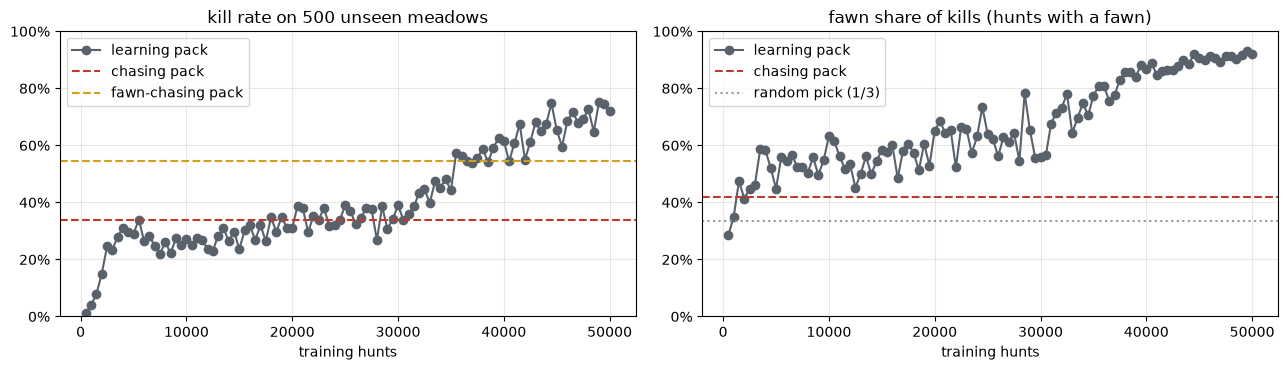

In [118]:
x, kill, bites, fawn = zip(*history)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
a1.plot(x, kill, "-o", color="#59616b", label="learning pack")
a1.axhline(baseline["chase"]["kill rate"], color="#c0392b", ls="--", label="chasing pack")
a1.axhline(baseline["fawn-chase"]["kill rate"], color="#d4a017", ls="--", label="fawn-chasing pack")
a1.set(title=f"kill rate on {len(TEST_ARENAS)} unseen meadows", xlabel="training hunts", ylim=(0, 1))
a2.plot(x, fawn, "-o", color="#59616b", label="learning pack")
a2.axhline(baseline["chase"]["fawn share of kills"], color="#c0392b", ls="--", label="chasing pack")
a2.axhline(1 / N_DEER, color="#999999", ls=":", label="random pick (1/3)")
a2.set(title="fawn share of kills (hunts with a fawn)", xlabel="training hunts", ylim=(0, 1))
for a in (a1, a2):
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 6. Head to head on 200 new meadows

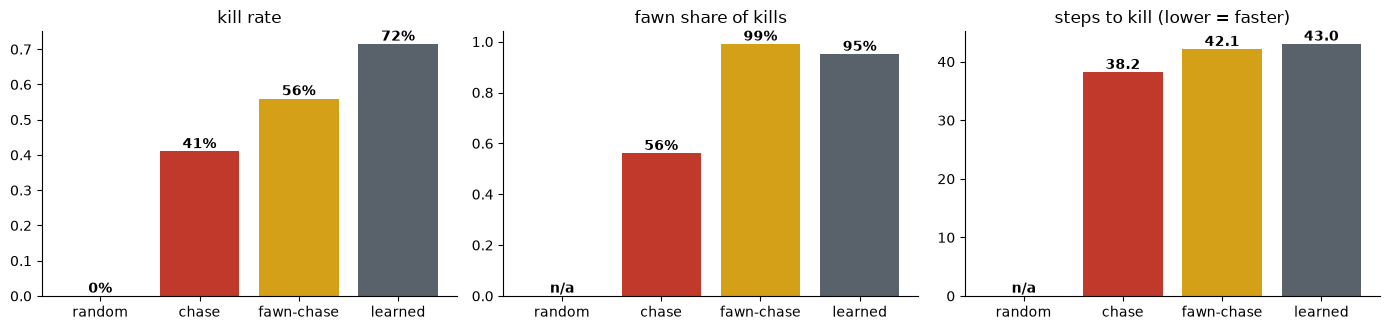

In [119]:
EVAL_ARENAS = [random_arena(np.random.default_rng(5000 + i)) for i in range(200)]
packs = {"random": random_policy, "chase": chase_policy, "fawn-chase": fawn_chase_policy,
         "learned": lambda o, e: act(net, o)}
results = {name: evaluate(p, EVAL_ARENAS) for name, p in packs.items()}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
colors = ["#bbbbbb", "#c0392b", "#d4a017", "#59616b"]
for ax, metric in zip(axes, ["kill rate", "fawn share of kills", "steps to kill"]):
    vals = [results[n][metric] for n in packs]
    ax.bar(list(packs), np.nan_to_num(vals), color=colors)
    for i, v in enumerate(vals):
        ax.text(i, np.nan_to_num(v), "n/a" if np.isnan(v) else (f"{v:.0%}" if metric != "steps to kill" else f"{v:.1f}"),
                ha="center", va="bottom", fontweight="bold")
    ax.set_title(metric + (" (lower = faster)" if metric == "steps to kill" else ""))
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Watch the hunt
Each row puts the **chasing pack** and the **learned pack** on the same meadow. The small spotted deer is the fawn; a killed deer fades out. Red bursts are bites. Use the controls, and re-run the cell for new meadows.

By default the meadows shown all include a fawn and are ones where the learned pack made a kill, so you can see which deer it went for. Set `ONLY_KILLS = False` or `ONLY_FAWN_MEADOWS = False` for unfiltered meadows.

In [120]:
PLAYER_JS = r"""
<script>
(function () {
  const D = __DATA__, C = __CELL__, uid = "__UID__", N = __N__;
  const slider = document.getElementById(uid + "_slider"), playBtn = document.getElementById(uid + "_play");
  let i = 0, timer = null;
  function place(el, r, c, f) {
    el.style.transform = "translate(" + (c + .5) * C + "px," + (r + .5) * C + "px)";
    el.firstChild.setAttribute("transform", "scale(" + f + ",1)");
  }
  function show(k) {
    i = k; slider.value = k;
    D.forEach(function (frames, p) {
      const f = frames[Math.min(k, frames.length - 1)], id = uid + "_" + p;
      f.deer.forEach(function (d, j) {
        const el = document.getElementById(id + "_d" + j);
        place(el, d[0], d[1], d[2]);
        el.style.opacity = f.killed.indexOf(j) >= 0 ? 0.35 : 1;
      });
      f.wolves.forEach(function (w, j) { place(document.getElementById(id + "_w" + j), w[0], w[1], w[2]); });
      f.wolves.forEach(function (w, j) {
        const b = document.getElementById(id + "_b" + j);
        if (j < f.bites.length) {
          b.setAttribute("x", (f.bites[j][1] + .5) * C - C * .3); b.setAttribute("y", (f.bites[j][0] + .5) * C - C * .3);
          b.setAttribute("visibility", "visible");
        } else b.setAttribute("visibility", "hidden");
      });
      let s = "step " + f.t;
      f.deer.forEach(function (d) {
        s += "  " + (d[3] ? "fawn " : "deer ") + "♥".repeat(d[4]) + "♡".repeat(__HP__ - d[4]);
      });
      if (f.bites.length) s += "  BITE x" + f.bites.length + "!";
      if (f.end === "kill") s += "  — KILL";
      if (f.end === "escaped") s += "  — deer escaped";
      document.getElementById(id + "_status").textContent = s;
    });
  }
  function stop() { clearInterval(timer); timer = null; playBtn.textContent = "▶ play"; }
  playBtn.onclick = function () {
    if (timer) return stop();
    if (i >= N - 1) show(0);
    playBtn.textContent = "⏸ pause";
    timer = setInterval(function () { if (i >= N - 1) stop(); else show(i + 1); }, 380);
  };
  document.getElementById(uid + "_prev").onclick = function () { stop(); show(Math.max(0, i - 1)); };
  document.getElementById(uid + "_next").onclick = function () { stop(); show(Math.min(N - 1, i + 1)); };
  slider.oninput = function () { stop(); show(+slider.value); };
  show(0);
})();
</script>"""

def hunt_player(panels, columns=2):
    """panels: list of (title, rocks, frames). Draws all panels with one shared set of controls."""
    uid = "hunt" + uuid.uuid4().hex[:8]
    n = max(len(frames) for _, _, frames in panels)
    btn = 'style="padding:3px 10px;margin-right:6px;cursor:pointer"'
    html = [SPRITES, f"<style>#{uid} .mover {{ transition: transform 0.3s ease-in-out; }}</style>", f'<div id="{uid}">',
            f'<div style="margin-bottom:8px"><button id="{uid}_play" {btn}>&#9654; play</button>'
            f'<button id="{uid}_prev" {btn}>&#9664; step</button><button id="{uid}_next" {btn}>step &#9654;</button>'
            f'<input id="{uid}_slider" type="range" min="0" max="{n - 1}" value="0" style="width:300px;vertical-align:middle"></div>',
            f'<div style="display:grid;grid-template-columns:repeat({columns}, max-content);gap:14px 22px">']
    for p, (title, rocks, frames) in enumerate(panels):
        f0 = frames[0]
        html.append(f'<div><div style="font-weight:600;margin-bottom:3px">{title}</div>'
                    f'{board_svg(f"{uid}_{p}", rocks, [d[:4] for d in f0["deer"]], f0["wolves"])}'
                    f'<div id="{uid}_{p}_status" style="font-family:monospace;margin-top:3px"></div></div>')
    html.append("</div></div>")
    js = (PLAYER_JS.replace("__DATA__", json.dumps([frames for _, _, frames in panels]))
          .replace("__CELL__", str(CELL)).replace("__UID__", uid).replace("__N__", str(n)).replace("__HP__", str(DEER_HP)))
    return HTML("".join(html) + js)

ONLY_KILLS = False          # show meadows where the learned pack made a kill (False = any meadow)
ONLY_FAWN_MEADOWS = False   # show only meadows that include a fawn

panels, tries = [], 0
while len(panels) < 4 and tries < 500:                          # re-run for new meadows
    tries += 1
    arena = EVAL_ARENAS[rng.integers(len(EVAL_ARENAS))]
    if ONLY_FAWN_MEADOWS and not any(arena[2]):
        continue
    learned = run_hunt(Hunt(*arena), packs["learned"])
    if ONLY_KILLS and learned[0] != "kill":
        continue
    chase = run_hunt(Hunt(*arena), packs["chase"])
    for name, (outcome, steps, n_bites, p, frames) in [("chase", chase), ("learned", learned)]:
        panels.append((f"{name} pack: {outcome}{f' ({p})' if p else ''}, {n_bites} bites", arena[0], frames))
display(hunt_player(panels) if panels else "no matching meadows found; try ONLY_KILLS = False")

## Things to try
- **Is the fawn really easier?** Compare the chasing and fawn-chasing baselines. If fawn-chasing doesn't kill more often, there's little for the pack to learn. Try `DEER_EXTRA_EVERY = 2` to make adults faster and the fawn relatively easier.
- **Blind wolves:** replace `float(self.fawn[k])` with `0.0` in `observe()`. The wolves can no longer tell which deer is the fawn, and with no memory they can't infer it from how it moves. The fawn share of kills should fall back toward what type-blind chasing gets.
- **Easy prey vs. a good meal:** give a fawn kill a smaller reward than an adult kill (for example 5 vs 15). Does the pack still go for the fawn, and at what ratio does it switch?
- `FAWN_CHANCE = 1.0`: a fawn in every hunt. Or `N_DEER = 1` with `FAWN_CHANCE = 0`, which is close to the original single-deer game (with the fixed shaping).
- **No shaping:** `CHASE_SHAPING = PIN_SHAPING = 0`. In tests the pack learned nothing at all without the hints: random wolves almost never land a kill to learn from.
- **"Fair" shaping:** make the hints potential-based (subtract the distance the deer gains back when it flees). It can't be farmed and in theory doesn't change the best strategy, but in tests the pack stayed at 0%. A nice example of theory vs. practice in reward design.
- `GAMMA`: shorter horizons make the pack prefer whatever is closest. A longer one (it's 0.975 here) lets it value walking past an adult to reach the fawn.